# Predict ordered class probabilities

Ordered categories have a meaningful ranking without a numeric distance between levels. We simulate a latent logistic response separated by thresholds, fit an ordered GAM, and inspect all three class probabilities.

The cumulative probability of category $k$ or below is the logistic CDF at $\alpha_k-\eta(x)$, where the thresholds $\alpha_k$ are ordered. Each category probability is the difference between adjacent cumulative probabilities, with tail probabilities at the two ends. Ordering the categories does not assume equal numerical spacing.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.model_selection import train_test_split
from nampy.gam import GAM

rng=np.random.default_rng(108)
data=pd.DataFrame({"x":rng.uniform(0,1,700)})
grid=pd.DataFrame({"x":np.linspace(0,1,180)})
from scipy.special import expit
eta=1.6*np.sin(2*np.pi*data.x)
latent=eta+rng.logistic(size=len(data))
data["y"]=np.digitize(latent,[-1.,1.])+1
train,test=train_test_split(data,test_size=.25,stratify=data.y,random_state=108)
model=GAM(formula="y ~ s(x,bs='cr',k=12)",family={"name":"ocat","R":3},optimize_smoothing=True,smoothing_method="reml").fit(train)
probability=np.asarray(model.predict(grid,type="response"))
eta_grid=1.6*np.sin(2*np.pi*grid.x)
cumulative=np.column_stack([expit(-1-eta_grid),expit(1-eta_grid)])
known=np.column_stack([cumulative[:,0],cumulative[:,1]-cumulative[:,0],1-cumulative[:,1]])


## Compare probabilities and test outcomes

Probability columns follow the ordered classes 1, 2, and 3. We assess the complete probability vector with log loss, rather than treating the class labels as continuous measurements.

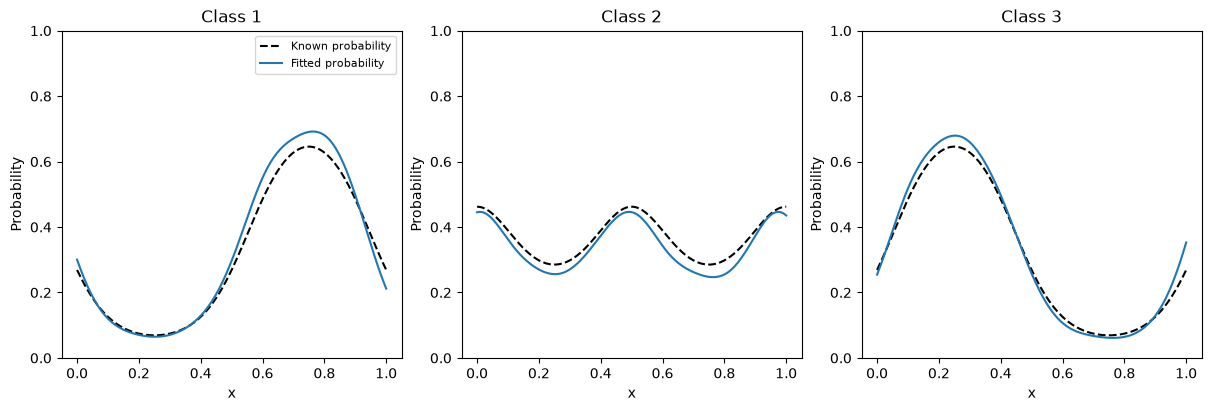

Test log loss
1.030


In [2]:
figure,axes=plt.subplots(1,3,figsize=(12,4),constrained_layout=True)
for column,axis in enumerate(axes):
    axis.plot(grid.x,known[:,column],"k--",label="Known probability")
    axis.plot(grid.x,probability[:,column],label="Fitted probability")
    axis.set(title=f"Class {column+1}",xlabel="x",ylabel="Probability",ylim=(0,1))
axes[0].legend(fontsize=8)
plt.show()
plt.close(figure)
from sklearn.metrics import log_loss
p_test=np.asarray(model.predict(test,type="response"))
pd.DataFrame({"Test log loss":[log_loss(test.y,p_test,labels=[1,2,3])]}).style.hide(axis="index").format("{:.3f}")

The probability panels show how mass shifts between the ordered classes as x changes, rather than assigning a numeric distance between labels. Test log loss is 1.030; lower values would indicate better probability predictions on these same rows. Compare the fitted curves with the known probabilities as well, since one aggregate score does not establish calibration throughout the predictor range.